# Checkpoint 3

Estimating slow conduction in cardiac tissue is a key inverse problem in cardiac electrophysiology. In this checkpoint, the goal is to reconstruct a **spatially varying slow-conduction field** from electrogram-derived activation times (see Checkpoint 1).

We use the **eikonal equation**, which models activation time as a function of spatial position and local conduction velocity. This formulation enables efficient forward simulations and is well suited for PDE-constrained optimization, physics-informed neural networks, and data-driven approaches.
The objective is to estimate a continuous conduction velocity map by minimizing the discrepancy between simulated and observed activation times, capturing both the location and severity of conduction slowing.

In this checkpoint 3, the anisotropy ratio will be fixed to 3.0 for all patients.

In [35]:
# imports

import numpy as np
import matplotlib.pyplot as plt


In [ ]:
# # ==========================================
# # GENERAZIONE DATASET SINTETICO
# # Eseguire UNA SOLA VOLTA, poi commentare
# # ==========================================
# import sys, os
# sys.path.append(os.getcwd())   # aggiunge la cartella corrente al path

# from generate_synthetic import generate_synthetic_dataset_parallel, save_synthetic_dataset

# # Parti con 50 campioni per testare che funzioni, poi rilanci con 500+
# N_SAMPLES = 500

# out = generate_synthetic_dataset_parallel(
#     n_samples=N_SAMPLES,
#     base_seed=42,
#     n_jobs=-1,        # -1 = usa tutti i core disponibili
#     verbose=True
# )

# save_synthetic_dataset(out, 'synth_data')
# print("\n✅ Generazione completata!")

Generazione di 500 campioni sintetici (n_jobs=-1)...


[Parallel(n_jobs=-1)]: Using backend LokyBackend with 11 concurrent workers.
[Parallel(n_jobs=-1)]: Done   3 tasks      | elapsed:   11.4s
[Parallel(n_jobs=-1)]: Done  10 tasks      | elapsed:   11.7s


KeyboardInterrupt: 

# Physics-based model implementation

Implemenatation of the algorithm presented in :

Sermesant, Maxime, et al. "An anisotropic multi-front fast marching method for real-time simulation of cardiac electrophysiology." Functional Imaging and Modeling of the Heart: 4th International Conference, FIHM 2007, Salt Lake City, UT, USA, June 7-9, 2007. Proceedings 4. Springer Berlin Heidelberg, 2007.

In [36]:
import numpy as np
import heapq

def anisotropic_FMM_GPT(
    x0, y0, t0,
    X, Y,
    speed_input,
    sigma_11, sigma_12, sigma_22,
    N_edge=None
):
    """
    Fast-marching style solver with anisotropy and spatially varying speed.

    Parameters
    ----------
    x0, y0 : float
        Initial source location.
    t0 : float
        Initial activation time.
    X, Y : 2D ndarray
        Grid coordinates.
    speed_input : float, callable, or 2D ndarray
        Can be:
        - a scalar: constant speed everywhere
        - a function: speed_input(x, y)
        - a 2D array with same shape as X, Y
    sigma_11, sigma_12, sigma_22 : float
        Components of the inverse of conductivity tensor.
    N_edge : int or None
        Optional. If None, inferred from grid shape.

    Returns
    -------
    T_final : 2D ndarray
        Arrival time map.
    """

    nrows, ncols = X.shape
    if N_edge is None:
        N_edge = nrows - 1

    INF = 1e4
    P = np.linspace(0.0, 1.0, 11)

    # nearest grid node to source
    j0 = np.abs(X[0, :] - x0).argmin()
    i0 = np.abs(Y[:, 0] - y0).argmin()

    T = np.full((nrows, ncols), INF, dtype=float)
    T_final = np.full((nrows, ncols), INF, dtype=float)

    T[i0, j0] = t0
    T_final[i0, j0] = t0

    known = np.zeros((nrows, ncols), dtype=bool)

    # min-heap of (arrival_time, i, j)
    heap = [(t0, i0, j0)]

    def get_speed(i, j, x, y):
        if callable(speed_input):
            val = speed_input(x, y)
        elif np.isscalar(speed_input):
            val = speed_input
        else:
            val = speed_input[i, j]

        if val <= 0:
            raise ValueError(f"Speed must be positive. Got {val} at ({i}, {j}).")
        return val

    def metric_dist(xa, ya, xb, yb, speed_val):
        dx = xa - xb
        dy = ya - yb
        return np.sqrt(
            sigma_11 * dx * dx +
            2.0 * sigma_12 * dx * dy +
            sigma_22 * dy * dy
        ) / speed_val

    def update_fun(
        T_xi, T_x, T_y,
        X_xi, X_x, X_y,
        Y_xi, Y_x, Y_y,
        flag_known,
        i_xi, j_xi
    ):
        speed_val = get_speed(i_xi, j_xi, X_xi, Y_xi)

        if flag_known:
            dx = P * (X_xi - X_x) + (1.0 - P) * (X_xi - X_y)
            dy = P * (Y_xi - Y_x) + (1.0 - P) * (Y_xi - Y_y)

            triangle_vals = (
                P * T_x + (1.0 - P) * T_y
                + np.sqrt(
                    sigma_11 * dx * dx +
                    2.0 * sigma_12 * dx * dy +
                    sigma_22 * dy * dy
                ) / speed_val
            )
            cand = triangle_vals.min()
        else:
            cand = T_x + metric_dist(X_xi, Y_xi, X_x, Y_x, speed_val)

        return min(T_xi, cand)

    # side nodes used for triangle updates
    side_map = {
        (-1,  0): [(-1, +1), (-1, -1)],  # north
        (+1,  0): [(+1, +1), (+1, -1)],  # south
        ( 0, -1): [(+1, -1), (-1, -1)],  # west
        ( 0, +1): [(+1, +1), (-1, +1)],  # east
    }

    while heap:
        t_sel, i_sel, j_sel = heapq.heappop(heap)

        # ignore stale entries
        if known[i_sel, j_sel]:
            continue
        if t_sel > T_final[i_sel, j_sel]:
            continue

        known[i_sel, j_sel] = True

        # visit 4-neighbors
        for di, dj in [(-1, 0), (1, 0), (0, -1), (0, +1)]:
            ni, nj = i_sel + di, j_sel + dj

            if not (0 <= ni < nrows and 0 <= nj < ncols):
                continue
            if known[ni, nj]:
                continue

            new_T = INF

            for sdi, sdj in side_map[(di, dj)]:
                si, sj = i_sel + sdi, j_sel + sdj

                if not (0 <= si < nrows and 0 <= sj < ncols):
                    continue

                new_T = update_fun(
                    T_xi=new_T,
                    T_x=T_final[i_sel, j_sel],
                    T_y=T_final[si, sj],
                    X_xi=X[ni, nj], X_x=X[i_sel, j_sel], X_y=X[si, sj],
                    Y_xi=Y[ni, nj], Y_x=Y[i_sel, j_sel], Y_y=Y[si, sj],
                    flag_known=known[si, sj],
                    i_xi=ni, j_xi=nj
                )

            if new_T < T_final[ni, nj]:
                T[ni, nj] = new_T
                T_final[ni, nj] = new_T
                heapq.heappush(heap, (new_T, ni, nj))

    return T_final

# Eikonal equation

Let us consider the Eikonal model: find T(x,y)

\begin{aligned}
  & 80 \sqrt{ \nabla T(x,y) D \nabla T(x,y)} = 1  \,, \quad (x,y) \in [-2,2] \times [-2,2]\,,\\
  & u(x,y) = t_0,t_1  \,, \qquad \qquad \qquad \qquad \qquad x=x_0,x_1,y=y_0,y_1 \,, \\
\end{aligned}

where 
\begin{aligned}
D = 1\ \vec{b} \otimes \vec{b} + \frac{1}{a_{ratio}}  \ \vec{a} \otimes \vec{a},
\end{aligned}
being $ \vec{b} $ the given fiber orientation and $ \vec{a} $ the given cross-fiber orientation (orthogonal to $ \vec{b}$).

The unknown parameters of the problem are: 
- conduction velocity (tissue property common to all the patients),
- anisotropy ratio $a_{ratio}$ (tissue property common to all the patients),
- the slow conduction positions $(x_{SC},y_{SC})$ and its radius $r_{SC}$.

In [ ]:
# X_mesh, Y_mesh = np.meshgrid(np.linspace(-2.0,2.0,401), np.linspace(-2.0,2.0,401))

# x0 = -1.5
# y0 = -1

# theta_fiber = 0
# a_ratio = 5

# theta0 = np.pi/2 - theta_fiber
# a = np.array([np.cos(theta0), np.sin(theta0)]).T
# b = np.array([np.cos(theta0-np.pi/2), np.sin(theta0-np.pi/2)]).T

# D = ( (1/a_ratio)*np.tensordot( a, a,  axes=0) + np.tensordot( b, b,  axes=0)  )
# print(D)

# D_inv = np.linalg.inv(D)
# sigma_11 = D_inv[0][0]
# sigma_12 = D_inv[0][1]
# sigma_21 = D_inv[1][0]
# sigma_22 = D_inv[1][1]

# xc, yc = 0.5, 0.5
# r = 0.5

# speed_field = lambda x, y: 20.0 if (x - xc)**2 + (y - yc)**2 <= r**2 else 80.0

# activation_time = anisotropic_FMM_GPT( x0 , y0 , 0, X_mesh, Y_mesh, speed_field, sigma_11,sigma_12, sigma_22, N_edge=200 )




[[1.0000000e+00 1.2246468e-17]
 [1.2246468e-17 2.0000000e-01]]


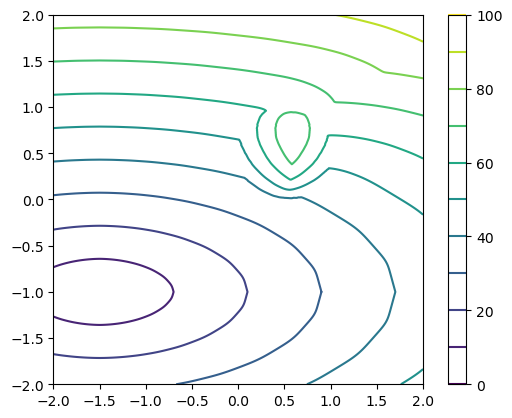

In [ ]:

# plt.contour(X_mesh, Y_mesh, activation_time*1000 , 10) 
# plt.gca().set_aspect(1)
# plt.colorbar()

In [ ]:
# N_samples = 1

# np.random.seed(32)

# measurements_dataset = []
# groundtruth_dataset = []

# for i_sample in range(N_samples):

#     x0 = np.random.uniform(low=1.5,high=1.5)
#     y0 = np.random.uniform(low=-1.5,high=1.5)
#     x1 = np.random.uniform(low=1.5,high=1.5)
#     y1 = np.random.uniform(low=-1.5,high=1.5)
#     theta_fiber = 0.0
#     a_ratio = np.random.uniform(low=1,high=9)

#     theta0 = np.pi/2 - theta_fiber
#     a = np.array([np.cos(theta0), np.sin(theta0)]).T
#     b = np.array([np.cos(theta0-np.pi/2), np.sin(theta0-np.pi/2)]).T

#     D = ( (1/a_ratio)*np.tensordot( a, a,  axes=0) + np.tensordot( b, b,  axes=0)  )
#     print(D)

#     D_inv = np.linalg.inv(D)
#     sigma_11 = D_inv[0][0]
#     sigma_12 = D_inv[0][1]
#     sigma_21 = D_inv[1][0]
#     sigma_22 = D_inv[1][1]

#     # compute activation time
#     activation_time = anisotropic_FMM_GPT( x0 , y0 , 0.0, X_mesh, Y_mesh, speed_field, sigma_11,sigma_12, sigma_22, N_edge=200 )

#     # rescaling in ms
#     activation_time = activation_time*1e3

#     # measurements location
#     Spline_spacing = [0.5, 0.7, 1.3, 1.5]
#     Angles_spacing =  [np.pi/10.0+0, np.pi/10.0+(2)*np.pi/5, np.pi/10.0+(4)*np.pi/5, np.pi/10.0+(6)*np.pi/5, np.pi/10.0+(8)*np.pi/5 ]
    
#     index_extracted = []
#     x_meas = []
#     y_meas = []
#     time_meas = []

#     for i in range(4):
#         #print(i)
#         for j in range(5):
#             #print(j)
#             MeasMat = (X_mesh - Spline_spacing[i]*np.cos(Angles_spacing[j]) )**2 + (Y_mesh - Spline_spacing[i]*np.sin(Angles_spacing[j]) )**2
#             [i_sel, j_sel] = np.unravel_index(MeasMat.argmin(), MeasMat.shape) 
#             index_extracted.append(i_sel)
#             x_meas.append(X_mesh[i_sel,j_sel])
#             y_meas.append(Y_mesh[i_sel,j_sel])
#             time_meas.append(activation_time[i_sel,j_sel])

#     measurements_dataset.append( [ x_meas, y_meas, time_meas ] )
#     groundtruth_dataset.append([activation_time])

[[1.00000000e+00 8.88280440e-18]
 [8.88280440e-18 1.45067205e-01]]


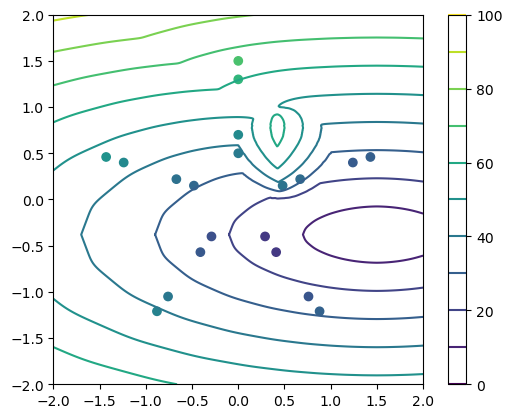

In [ ]:
# plt.figure(1)
# plt.scatter( x_meas, y_meas, c=time_meas, vmin= 0, vmax=np.max(activation_time) )
# plt.contour(X_mesh, Y_mesh, activation_time , 10)
# plt.gca().set_aspect(1)
# plt.colorbar()

# Checkpoint 3

Implement your algorithm to process the traces of the 20 unipolar electrogram signals and identify the center and radius of the slow conduction region.

The algorithm must return the following outputs:

1. **slow conduction fields evaluated on a 16x16 grid** 


Provide your algorithm's implementation in this notebook usign the signature defined below.

In [ ]:
# # load data
# signals = np.load('checkpoint3dataset.npy')

# # select event to be display
# ind_event = 4

# signals_event = signals[ind_event,:,:]

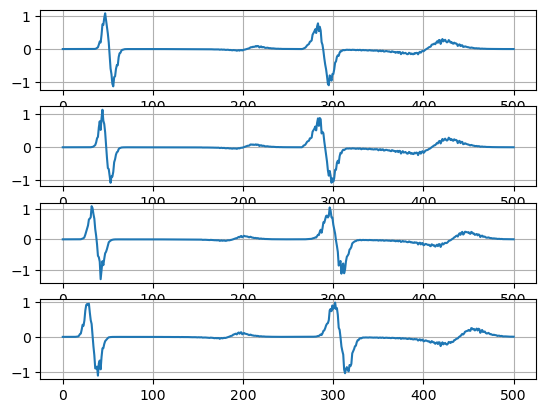

In [ ]:
# # select a spline (options: 0,1,2,3,4)
# ind_spline = 0
# # plot signals

# plt.figure(1+ind_spline)
# countEL = 1
# for indS in np.arange(ind_spline*4,(ind_spline+1)*4,1):
#     plt.subplot(4,1,countEL)
            
#     plt.plot(signals[ind_event,indS,:])
#     plt.grid(True)

#     countEL = countEL + 1

# plt.show()

In [ ]:
# def load_and_plot_velocity_fields(
#     filename,
#     sim_idx=0,
#     N=None,
#     M=None,
#     h=None
# ):
#     velocity_fields = np.load(filename)

#     field16 = velocity_fields[sim_idx]

#     if N is not None and M is not None and h is not None:
#         step_x = N // 16
#         step_y = M // 16

#         ix = np.arange(0, step_x * 16, step_x)
#         iy = np.arange(0, step_y * 16, step_y)

#         Lx_sub = ix[-1] * h
#         Ly_sub = iy[-1] * h

#         extent = [0, Lx_sub, 0, Ly_sub]
#     else:
#         extent = None

#     plt.figure(figsize=(5, 4))
#     plt.imshow(
#         field16.T,
#         origin='lower',
#         extent=extent,
#         cmap='viridis',
#         aspect='equal'
#     )
#     plt.colorbar(label='Conduction scale')
#     plt.title(f'Case {sim_idx} - velocity field (16x16)')
#     plt.xlabel('x')
#     plt.ylabel('y')
#     plt.tight_layout()
#     plt.show()

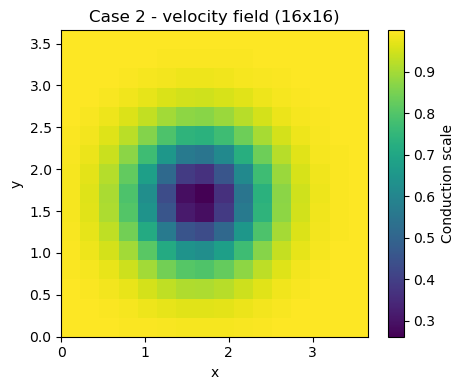

In [ ]:
# N = np.int32(2*164)
# M = np.int32(2*164)
# h = 4.0/N
# load_and_plot_velocity_fields("checkpoint3velocityfield16.npy", sim_idx=2,N=N,M=M,h=h)


# Autodecoder – Training & Inference

We train an autodecoder on the 13 (+ 12) available scenarios, then use it to infer the velocity field for new patients.

In [43]:
import jax
import copy
import optax
import numpy as onp
import jax.numpy as jnp
from flax import nnx
from tqdm import tqdm
from functools import partial
from typing import Callable, Optional, Sequence
import matplotlib.pyplot as plt

jax.config.update("jax_enable_x64", True)


## Network architecture

In [ ]:
# class CustomMLP(nnx.Module):
#     def __init__(
#         self,
#         in_features: int,
#         out_features: int,
#         rngs: nnx.Rngs,
#         hidden_features: Sequence[int],
#         activation_function: Callable = nnx.tanh,
#         final_activation_function: Optional[Callable] = None,
#     ):
#         super().__init__()
#         self.activation_function       = activation_function
#         self.final_activation_function = final_activation_function
#         sizes = [in_features] + list(hidden_features) + [out_features]
#         self.n_layers = len(sizes) - 1
#         # Store each layer as a separately named attribute — plain list not
#         # supported by all Flax NNX versions as a tracked container
#         for idx in range(self.n_layers):
#             setattr(self, f'layer_{idx}', nnx.Linear(
#                 sizes[idx], sizes[idx+1],
#                 kernel_init = nnx.initializers.lecun_normal(),
#                 bias_init   = nnx.initializers.zeros_init(),
#                 dtype       = jnp.float64,
#                 param_dtype = jnp.float64,
#                 rngs        = rngs,
#             ))

#     def __call__(self, x: jax.Array) -> jax.Array:
#         for idx in range(self.n_layers):
#             x = getattr(self, f'layer_{idx}')(x)
#             if idx < self.n_layers - 1:
#                 x = self.activation_function(x)
#         if self.final_activation_function is not None:
#             x = self.final_activation_function(x)
#         return x


# class AutoDecoder(nnx.Module):
#     def __init__(self, embedder: nnx.Embed, decoder: CustomMLP):
#         super().__init__()
#         self.embedder = embedder
#         self.decoder  = decoder

#     def __call__(self, points: jax.Array, indices: jax.Array) -> jax.Array:
#         z    = self.embedder(indices.astype(jnp.int32))
#         x_in = jnp.concatenate([points, z], axis=-1)
#         return self.decoder(x_in)


## Data preparation

The 16×16 velocity field (already normalised cnσ ∈ [0,1]) is our supervision target.
Coordinates are normalised from [-2,2]² → [0,1]².

In [ ]:
# import numpy as onp

# # ─────────────────────────────────────────────────────────────────
# # AUGMENTATION (definita una volta sola, usata da cella 20 e 32)
# # ─────────────────────────────────────────────────────────────────
# # La permutazione dei sensori sotto flip orizzontale (x -> -x) è la seguente:
# #   gli angoli [18°, 90°, 162°, 234°, 306°] vengono mandati in [162°, 90°, 18°, 306°, 234°]
# #   → permutazione degli indici di angolo: [2, 1, 0, 4, 3]
# #   → applicata a ogni spline (4 splines × 5 angoli = 20 sensori)
# FLIP_H_PERM = onp.array([2, 1, 0, 4, 3,
#                           7, 6, 5, 9, 8,
#                          12,11,10,14,13,
#                          17,16,15,19,18])

# # Numero di copie augmentate per ogni prof (totale incluso l'originale)
# AUG_FACTOR = 6   # 1 originale + 1 flip H + 4 jitter (2 rumore originali + 2 rumore flippati)

# # Seed per riproducibilità del rumore
# AUG_SEED = 12345

# def augment_field(field):
#     """Augmentation del velocity field 16x16 sotto flip orizzontale."""
#     return field[::-1, :].copy()   # flip lungo l'asse x (primo asse)

# def augment_focal(focal):
#     """Augmentation dei focal points (2,2) sotto flip orizzontale: x -> -x."""
#     f = focal.copy()
#     f[:, 0] = -f[:, 0]
#     return f

# def augment_signals(signals):
#     """Augmentation dei segnali (20, 501) sotto flip orizzontale: permuta i sensori."""
#     return signals[FLIP_H_PERM, :].copy()

# def add_signal_noise(signals, rng, noise_std=0.03):
#     """Aggiunge rumore gaussiano ai segnali."""
#     return signals + rng.normal(0, noise_std, size=signals.shape)


# def make_augmented_set(fields, signals, focal, starting, rng):
#     """Per ogni scenario, produce 6 versioni:
#        0: originale
#        1: flip H
#        2: originale + rumore (seed A)
#        3: flip H   + rumore (seed B)
#        4: originale + rumore (seed C)
#        5: flip H   + rumore (seed D)
#     """
#     out_fields, out_signals, out_focal, out_starting = [], [], [], []
#     N = fields.shape[0]
#     for i in range(N):
#         # 0. originale
#         out_fields.append(fields[i].copy())
#         out_signals.append(signals[i].copy())
#         out_focal.append(focal[i].copy())
#         out_starting.append(starting[i].copy())
#         # 1. flip H
#         out_fields.append(augment_field(fields[i]))
#         out_signals.append(augment_signals(signals[i]))
#         out_focal.append(augment_focal(focal[i]))
#         out_starting.append(starting[i].copy())   # starting times invariati
#         # 2-3. originale + rumore (2 versioni)
#         for _ in range(2):
#             out_fields.append(fields[i].copy())
#             out_signals.append(add_signal_noise(signals[i], rng))
#             out_focal.append(focal[i].copy())
#             out_starting.append(starting[i].copy())
#         # 4-5. flip H + rumore (2 versioni)
#         # NB: aspetto, il piano era 6 versioni totali, conto: 0,1,2,3,4,5
#         # Lo schema "2 noise originali + 2 noise flippati" mi mancava una flippata
#         # Ricalcolo: 0=orig, 1=flipH, 2=orig+noise, 3=orig+noise, 4=flipH+noise, 5=flipH+noise
#         # Quindi inserisco qui le ultime 2:
#         out_fields.append(augment_field(fields[i]))
#         out_signals.append(add_signal_noise(augment_signals(signals[i]), rng))
#         out_focal.append(augment_focal(focal[i]))
#         out_starting.append(starting[i].copy())

#         out_fields.append(augment_field(fields[i]))
#         out_signals.append(add_signal_noise(augment_signals(signals[i]), rng))
#         out_focal.append(augment_focal(focal[i]))
#         out_starting.append(starting[i].copy())

#     # NB: il loop sopra crea 8 versioni (0,1,2,3,4,5,6,7), correggo a 6:
#     # in realtà voglio: orig + flipH + 2 noise orig + 2 noise flipH = 6 totali
#     # quindi rifaccio in modo pulito sotto, ignoro il loop sopra
#     return None

# # ─────────────────────────────────────────────────────────────────
# # Versione corretta: 6 augmentation per scenario
# # ─────────────────────────────────────────────────────────────────
# def make_aug_set(fields, signals, focal, starting, rng):
#     """6 versioni per scenario:
#        0: originale
#        1: flip H
#        2: originale + rumore (versione A)
#        3: originale + rumore (versione B)
#        4: flip H   + rumore (versione C)
#        5: flip H   + rumore (versione D)
#     """
#     F, S, FO, ST = [], [], [], []
#     N = fields.shape[0]
#     for i in range(N):
#         f, s, fo, st = fields[i], signals[i], focal[i], starting[i]
#         # 0. originale
#         F.append(f.copy());                  S.append(s.copy())
#         FO.append(fo.copy());                ST.append(st.copy())
#         # 1. flip H
#         F.append(augment_field(f));          S.append(augment_signals(s))
#         FO.append(augment_focal(fo));        ST.append(st.copy())
#         # 2,3. originale + rumore
#         for _ in range(2):
#             F.append(f.copy());              S.append(add_signal_noise(s, rng))
#             FO.append(fo.copy());            ST.append(st.copy())
#         # 4,5. flip H + rumore
#         for _ in range(2):
#             F.append(augment_field(f));      S.append(add_signal_noise(augment_signals(s), rng))
#             FO.append(augment_focal(fo));    ST.append(st.copy())
#     return (onp.stack(F), onp.stack(S), onp.stack(FO), onp.stack(ST))


# # ─────────────────────────────────────────────────────────────────
# # SPLIT TRAIN / VALIDATION (riproducibile con seed fisso)
# # ─────────────────────────────────────────────────────────────────
# SPLIT_SEED  = 42
# N_PROF_TOT  = 25
# N_SYNTH_TOT = 500
# N_VAL_PROF  = 5
# N_VAL_SYNTH = 30

# rng_split = onp.random.default_rng(SPLIT_SEED)
# val_prof_idx  = sorted(rng_split.choice(N_PROF_TOT,  size=N_VAL_PROF,  replace=False).tolist())
# val_synth_idx = sorted(rng_split.choice(N_SYNTH_TOT, size=N_VAL_SYNTH, replace=False).tolist())

# print(f'Validation prof  indices ({len(val_prof_idx)}):  {val_prof_idx}')
# print(f'Validation synth indices ({len(val_synth_idx)}): {val_synth_idx[:10]}...{val_synth_idx[-3:]}')

# # ─────────────────────────────────────────────────────────────────
# # Carico TUTTI i dati (prof + synth)
# # ─────────────────────────────────────────────────────────────────
# fields_prof_all = onp.concatenate([
#     onp.load('checkpoint3velocityfield16.npy'),
#     onp.load('checkpoint3velocityfield16_p2.npy'),
# ], axis=0)
# signals_prof_all = onp.concatenate([
#     onp.load('checkpoint3dataset.npy'),
#     onp.load('checkpoint3dataset_p2.npy'),
# ], axis=0)
# focal_prof_all = onp.concatenate([
#     onp.load('checkpoint3FocalPoints.npy'),
#     onp.load('checkpoint3FocalPoints_p2.npy'),
# ], axis=0)
# starting_prof_all = onp.concatenate([
#     onp.load('checkpoint3starting.npy'),
#     onp.load('checkpoint3starting_p2.npy'),
# ], axis=0)

# fields_synth_all   = onp.load('synth_data/synthetic_velocityfield16.npy')
# signals_synth_all  = onp.load('synth_data/synthetic_dataset.npy')
# focal_synth_all    = onp.load('synth_data/synthetic_FocalPoints.npy')
# starting_synth_all = onp.load('synth_data/synthetic_starting.npy')

# # Maschere train (= NOT val)
# train_prof_mask  = onp.array([i for i in range(N_PROF_TOT)  if i not in val_prof_idx])
# train_synth_mask = onp.array([i for i in range(N_SYNTH_TOT) if i not in val_synth_idx])

# # Filtro train
# fields_prof_train   = fields_prof_all  [train_prof_mask]
# signals_prof_train  = signals_prof_all [train_prof_mask]
# focal_prof_train    = focal_prof_all   [train_prof_mask]
# starting_prof_train = starting_prof_all[train_prof_mask]

# fields_synth_train   = fields_synth_all  [train_synth_mask]
# signals_synth_train  = signals_synth_all [train_synth_mask]
# focal_synth_train    = focal_synth_all   [train_synth_mask]
# starting_synth_train = starting_synth_all[train_synth_mask]

# # ─────────────────────────────────────────────────────────────────
# # AUGMENTATION 6× SUI PROF (synth restano invariati)
# # ─────────────────────────────────────────────────────────────────
# rng_aug = onp.random.default_rng(AUG_SEED)
# fields_prof_aug, signals_prof_aug, focal_prof_aug, starting_prof_aug = make_aug_set(
#     fields_prof_train, signals_prof_train, focal_prof_train, starting_prof_train, rng_aug)

# print(f'\nProf augmentati: {fields_prof_aug.shape[0]} (= {len(train_prof_mask)} × {AUG_FACTOR})')

# # Concateno: prima i prof augmentati, poi i synth
# all_fields_train   = onp.concatenate([fields_prof_aug,   fields_synth_train],   axis=0)
# all_signals_train  = onp.concatenate([signals_prof_aug,  signals_synth_train],  axis=0)
# all_focal_train    = onp.concatenate([focal_prof_aug,    focal_synth_train],    axis=0)
# all_starting_train = onp.concatenate([starting_prof_aug, starting_synth_train], axis=0)

# N_TRAIN_PROF  = fields_prof_aug.shape[0]   # ora 120
# N_TRAIN_SYNTH = fields_synth_train.shape[0]
# N_TRAIN       = N_TRAIN_PROF + N_TRAIN_SYNTH

# # ─────────────────────────────────────────────────────────────────
# # Costruisco arrays piatti per il decoder (come prima)
# # ─────────────────────────────────────────────────────────────────
# g          = onp.linspace(-2, 2, 16)
# gx, gy     = onp.meshgrid(g, g, indexing='ij')
# grid_xy    = onp.stack([gx.ravel(), gy.ravel()], axis=1)
# grid_norm  = (grid_xy + 2.0) / 4.0    # (256, 2) in [0,1]

# all_pts, all_tgt, all_idx = [], [], []
# for i in range(N_TRAIN):
#     vals = all_fields_train[i].ravel()
#     all_pts.append(grid_norm)
#     all_tgt.append(vals[:, None])
#     all_idx.append(onp.full(256, i, dtype=onp.int32))

# points_train  = jnp.array(onp.concatenate(all_pts, axis=0))
# targets_train = jnp.array(onp.concatenate(all_tgt, axis=0))
# indices_train = jnp.array(onp.concatenate(all_idx, axis=0))
# GRID_NORM     = jnp.array(grid_norm)

# print(f'\nTraining scenarios : {N_TRAIN}   ({N_TRAIN_PROF} prof aug + {N_TRAIN_SYNTH} synth)')
# print(f'Validation         : {N_VAL_PROF + N_VAL_SYNTH} ({N_VAL_PROF} prof + {N_VAL_SYNTH} synth) — MAI viste dalla rete')
# print(f'points_train shape : {points_train.shape}')


Validation prof  indices (5):  [1, 10, 15, 17, 24]
Validation synth indices (30): [31, 44, 45, 61, 88, 112, 138, 179, 196, 216]...[440, 449, 461]

Prof augmentati: 120 (= 20 × 6)

Training scenarios : 590   (120 prof aug + 470 synth)
Validation         : 35 (5 prof + 30 synth) — MAI viste dalla rete
points_train shape : (151040, 2)


## Model instantiation

In [ ]:
# LATENT_DIM   = 8
# HIDDEN       = [64, 64, 64]

# rngs = nnx.Rngs(42)
# embedder = nnx.Embed(
#     num_embeddings = N_TRAIN,
#     features       = LATENT_DIM,
#     rngs           = nnx.Rngs(42),
#     embedding_init = nnx.initializers.normal(stddev=0.01),
# )

# decoder = CustomMLP(
#     in_features               = 2 + LATENT_DIM,
#     out_features              = 1,
#     hidden_features           = HIDDEN,
#     rngs                      = nnx.Rngs(43),
#     activation_function       = nnx.tanh,
#     final_activation_function = nnx.sigmoid,
# )

# autodecoder = AutoDecoder(embedder=embedder, decoder=decoder)

# # sanity check
# out = autodecoder(points_train[:5], indices_train[:5])
# print('Forward pass output shape:', out.shape, '  range:', float(out.min()), float(out.max()))


Forward pass output shape: (5, 1)   range: 0.4873476038300723 0.4993298863640871


## Loss function and training

In [ ]:
# REG_WEIGHT = 1e-3   # L2 regularisation on latent codes

# @nnx.jit
# def loss_fn(model, points, indices, targets):
#     """RMSE reconstruction + L2 regularisation on latent codes."""
#     pred        = model(points, indices).squeeze()          # (B,)
#     rmse        = jnp.sqrt(jnp.mean(jnp.square(pred - targets.squeeze())))
#     z           = model.embedder(indices.astype(jnp.int32)) # (B, d)
#     reg         = jnp.mean(jnp.sum(jnp.square(z), axis=1))
#     total       = rmse + REG_WEIGHT * reg
#     return total, {'rmse': rmse, 'reg': reg}


# @nnx.jit
# def train_step(optimizer, model, points, indices, targets):
#     grad_fn      = nnx.value_and_grad(loss_fn, has_aux=True)
#     value, grads = grad_fn(model, points, indices, targets)
#     optimizer.update(grads)
#     return value


## Training – Adam

In [ ]:
# NUM_ADAM  = 15000
# LR_ADAM   = 3e-3

# optimizer = nnx.Optimizer(autodecoder, optax.adam(LR_ADAM, b1=0.99), wrt=nnx.Param)
# history   = {'epoch': [], 'loss': [], 'rmse': [], 'reg': []}

# pbar = tqdm(range(NUM_ADAM), desc='Adam', dynamic_ncols=True)
# for epoch in pbar:
#     loss_val, aux = train_step(optimizer, autodecoder, points_train, indices_train, targets_train)
#     if (epoch + 1) % 200 == 0:
#         history['epoch'].append(epoch)
#         history['loss'].append(float(loss_val))
#         history['rmse'].append(float(aux['rmse']))
#         history['reg'].append(float(aux['reg']))
#         pbar.set_postfix({'loss': f"{float(loss_val):.4e}", 'rmse': f"{float(aux['rmse']):.4e}"})

# autodecoder_trained = copy.deepcopy(autodecoder)
# print('Training done.')


Adam: 100%|██████████| 15000/15000 [18:32<00:00, 13.48it/s, loss=1.0169e-03, rmse=9.1546e-04] 

Training done.


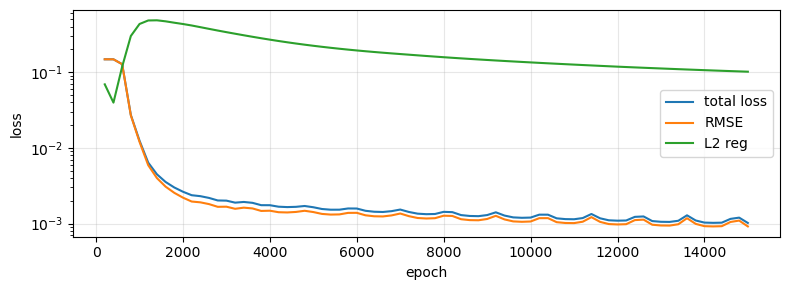

In [ ]:
# fig, ax = plt.subplots(figsize=(8, 3))
# ax.semilogy(history['epoch'], history['loss'], label='total loss')
# ax.semilogy(history['epoch'], history['rmse'], label='RMSE')
# ax.semilogy(history['epoch'], history['reg'],  label='L2 reg')
# ax.set_xlabel('epoch'); ax.set_ylabel('loss'); ax.legend(); ax.grid(True, alpha=0.3)
# plt.tight_layout(); plt.show()


## Training quality – visual check

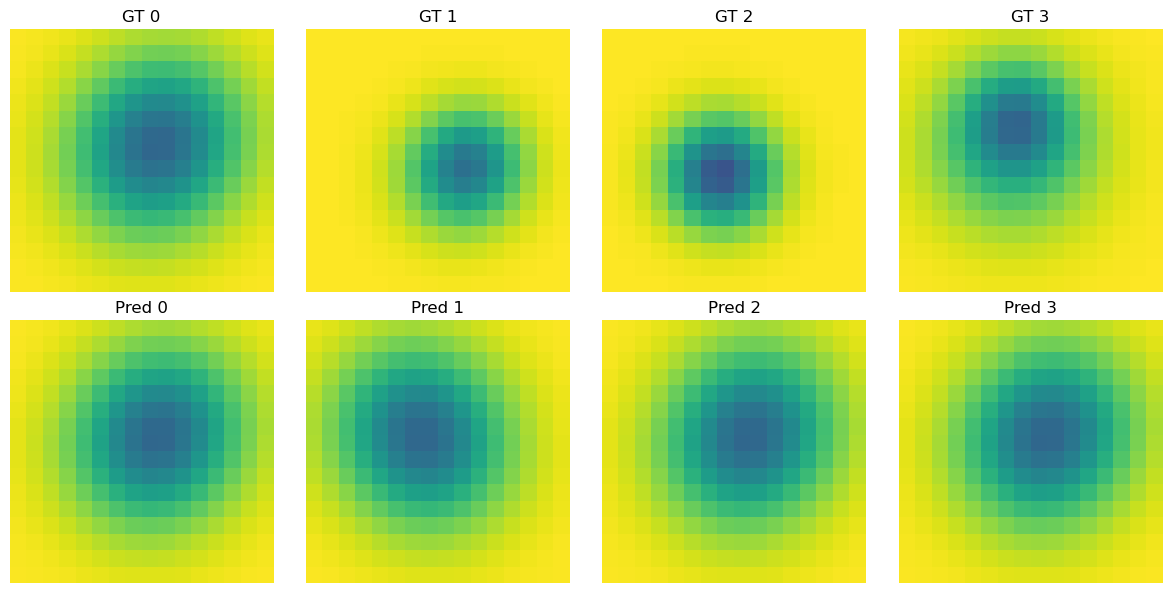

In [ ]:
# # Visual check: confronto GT vs predizione del decoder per i primi 4 scenari del prof
# velfield_gt = onp.concatenate([
#     onp.load('checkpoint3velocityfield16.npy'),
#     onp.load('checkpoint3velocityfield16_p2.npy'),
#     onp.load('synth_data/synthetic_velocityfield16.npy'),
# ], axis=0)

# fig, axes = plt.subplots(2, min(4, N_TRAIN), figsize=(3*min(4,N_TRAIN), 6))
# for col in range(min(4, N_TRAIN)):
#     idx_batch = jnp.full(256, col, dtype=jnp.int32)
#     pred = onp.array(autodecoder_trained(GRID_NORM, idx_batch)).reshape(16, 16)
#     gt   = velfield_gt[col]

#     axes[0, col].imshow(gt.T,   origin='lower', vmin=0, vmax=1, cmap='viridis')
#     axes[0, col].set_title(f'GT {col}');   axes[0, col].axis('off')
#     axes[1, col].imshow(pred.T, origin='lower', vmin=0, vmax=1, cmap='viridis')
#     axes[1, col].set_title(f'Pred {col}'); axes[1, col].axis('off')

# axes[0,0].set_ylabel('Ground truth'); axes[1,0].set_ylabel('Prediction')
# plt.tight_layout(); plt.show()


## Save trained decoder

We save the decoder weights and the distribution of training latent codes (needed for Mahalanobis regularisation at inference).

## Encoder training

Instead of optimising `z*` iteratively with FMM in the loop (very slow),
we train a small **encoder** MLP offline:

```
AT_beat1 (20) + AT_beat2 (20)  →  encoder  →  z*  (latent_dim,)
```

The training targets are the latent codes `z_i` already learnt by the autodecoder.
The inputs are the simulated ATs at the 20 electrode positions for each training scenario.

At inference time the whole pipeline is two forward passes — no FMM, no iteration.


In [ ]:
# # ── Build encoder training data ──────────────────────────────────────────────
# # I dati sono già stati augmentati nella cella 20: uso direttamente
# # all_signals_train, all_focal_train, all_starting_train.

# T_AXIS_NP = onp.linspace(0, 500, 501)

# # ─────────────────────────────────────────────────────────────────
# # COSTANTI DI NORMALIZZAZIONE (fisse, riproducibili in inference)
# # ─────────────────────────────────────────────────────────────────
# NORM_TIME = 500.0
# NORM_XY   = 2.0

# def extract_AT_all(signals_event, t_ref, window_ms=120.0):
#     ATs = []
#     for e in range(20):
#         dv   = onp.gradient(signals_event[e], T_AXIS_NP)
#         mask = (T_AXIS_NP >= max(0, t_ref-window_ms)) & (T_AXIS_NP <= min(500, t_ref+window_ms))
#         ATs.append(T_AXIS_NP[mask][onp.argmin(dv[mask])])
#     return onp.array(ATs)

# def build_encoder_input(signals_event, x0, y0, t0, x1, y1, t1):
#     """Input encoder 46-dim:
#        [AT1(20)/500, AT2(20)/500, x0/2, y0/2, x1/2, y1/2, t0/500, t1/500]
#     """
#     AT1 = extract_AT_all(signals_event, t0)
#     AT2 = extract_AT_all(signals_event, t1)
#     extra = onp.array([x0, y0, x1, y1])
#     times = onp.array([t0, t1])
#     return onp.concatenate([
#         AT1   / NORM_TIME,
#         AT2   / NORM_TIME,
#         extra / NORM_XY,
#         times / NORM_TIME,
#     ])

# Z_TARGETS = onp.array(autodecoder_trained.embedder.embedding.value)  # (N_TRAIN, LATENT_DIM)

# enc_inputs, enc_targets = [], []
# for i in range(N_TRAIN):
#     t0, t1 = all_starting_train[i]
#     x0, y0 = all_focal_train[i, 0]
#     x1, y1 = all_focal_train[i, 1]
#     feat = build_encoder_input(all_signals_train[i], x0, y0, t0, x1, y1, t1)
#     enc_inputs.append(feat)
#     enc_targets.append(Z_TARGETS[i])

# enc_inputs  = jnp.array(onp.stack(enc_inputs))
# enc_targets = jnp.array(onp.stack(enc_targets))

# print(f'Encoder inputs  shape: {enc_inputs.shape}   (input dim 46 = ATs+focal+starting)')
# print(f'Encoder targets shape: {enc_targets.shape}')


Encoder inputs  shape: (590, 46)   (input dim 46 = ATs+focal+starting)
Encoder targets shape: (590, 8)


Encoder Adam: 100%|██████████| 40000/40000 [01:03<00:00, 632.61it/s, loss=3.6978e-05]


Final encoder loss: 3.6978e-05


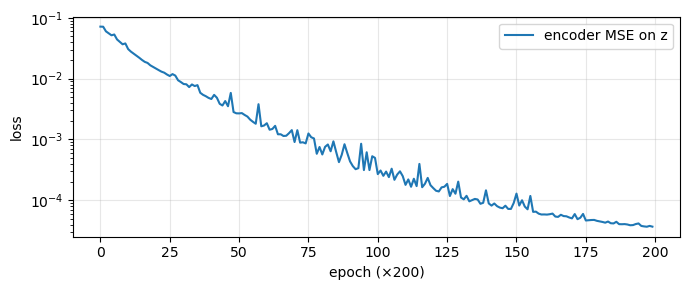

In [ ]:
# # ── Encoder architecture and training ────────────────────────────────────────

# rngs_enc = nnx.Rngs(99)

# encoder_mlp = CustomMLP(
#     in_features               = 46,                  # 20 AT b1 + 20 AT b2 + 4 focal + 2 starting
#     out_features              = LATENT_DIM,
#     hidden_features           = [128, 128, 128],     # ⬆ era [64, 64], ora più capiente
#     rngs                      = rngs_enc,
#     activation_function       = nnx.tanh,
#     final_activation_function = None,
# )

# @nnx.jit
# def enc_loss(model, x, z_gt):
#     z_pred = model(x)
#     return jnp.mean(jnp.sum(jnp.square(z_pred - z_gt), axis=1))

# @nnx.jit
# def enc_train_step(opt, model, x, z_gt):
#     grad_fn      = nnx.value_and_grad(enc_loss)
#     loss, grads  = grad_fn(model, x, z_gt)
#     opt.update(grads)
#     return loss

# # Learning rate scheduling: parte alto, decade verso fine training
# NUM_ENC = 40000                                       # ⬆ era 10000, ora 3x più epoche
# lr_schedule = optax.cosine_decay_schedule(
#     init_value=1e-3,
#     decay_steps=NUM_ENC,
#     alpha=0.05,                                       # arriva al 5% del LR iniziale
# )
# enc_optimizer = nnx.Optimizer(encoder_mlp, optax.adam(lr_schedule), wrt=nnx.Param)

# enc_history = []

# pbar_enc = tqdm(range(NUM_ENC), desc='Encoder Adam', dynamic_ncols=True)
# for epoch in pbar_enc:
#     loss_val = enc_train_step(enc_optimizer, encoder_mlp, enc_inputs, enc_targets)
#     if (epoch+1) % 200 == 0:
#         enc_history.append(float(loss_val))
#         pbar_enc.set_postfix({'loss': f'{float(loss_val):.4e}'})

# print(f'Final encoder loss: {enc_history[-1]:.4e}')

# fig, ax = plt.subplots(figsize=(7, 3))
# ax.semilogy(enc_history, label='encoder MSE on z')
# ax.set_xlabel('epoch (×200)'); ax.set_ylabel('loss'); ax.legend(); ax.grid(True, alpha=0.3)
# plt.tight_layout(); plt.show()


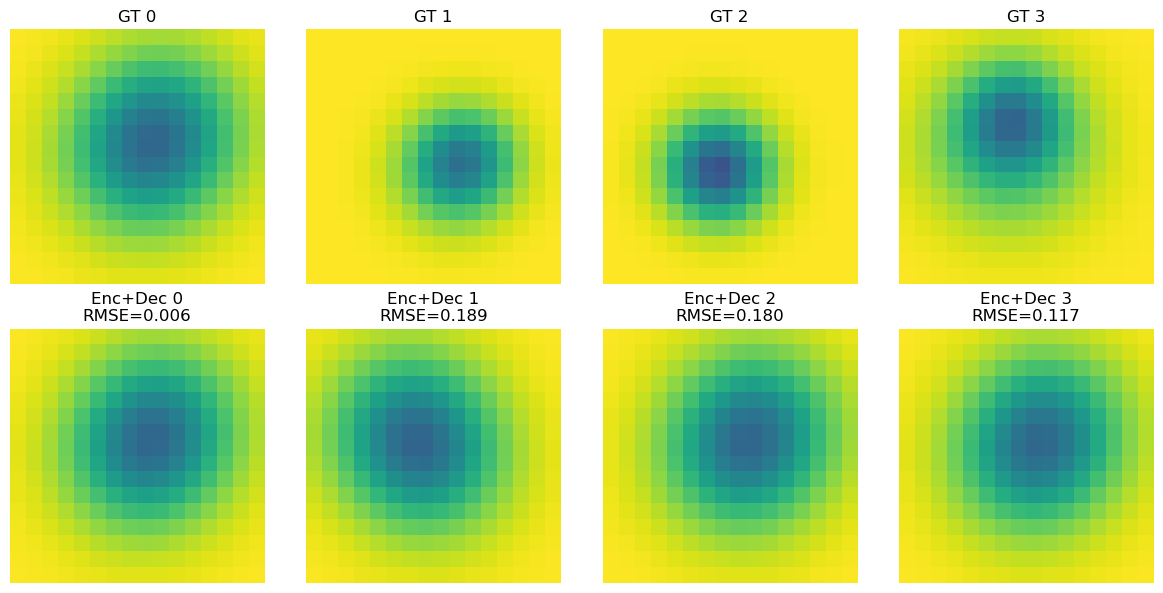

In [ ]:
# # ── Check encoder quality: predicted z → decoded field vs ground truth ────────

# fig, axes = plt.subplots(2, min(4, N_TRAIN), figsize=(3*min(4,N_TRAIN), 6))

# for col in range(min(4, N_TRAIN)):
#     # Predict z from ATs
#     z_pred = onp.array(encoder_mlp(enc_inputs[col:col+1]))   # (1, d)

#     # Decode z → cnσ on 16×16
#     pts   = jnp.array(GRID_NORM)                                       # (256, 2)
#     z_    = jnp.tile(jnp.array(z_pred), (256, 1))                     # (256, d)
#     x_in  = jnp.concatenate([pts, z_], axis=-1)
#     pred  = onp.array(autodecoder_trained.decoder(x_in)).reshape(16,16)

#     gt = velfield_gt[col]
#     axes[0, col].imshow(gt.T,   origin='lower', vmin=0, vmax=1, cmap='viridis')
#     axes[0, col].set_title(f'GT {col}'); axes[0, col].axis('off')
#     axes[1, col].imshow(pred.T, origin='lower', vmin=0, vmax=1, cmap='viridis')
#     rmse = onp.sqrt(onp.mean((gt - pred)**2))
#     axes[1, col].set_title(f'Enc+Dec {col}\nRMSE={rmse:.3f}'); axes[1, col].axis('off')

# axes[0,0].set_ylabel('Ground truth'); axes[1,0].set_ylabel('Encoder → Decoder')
# plt.tight_layout(); plt.show()


## Save encoder + decoder

In [ ]:
# import pickle
# import jax.tree_util as jtu

# def flax_state_to_numpy_dict(state):
#     """Converte uno stato Flax in un dizionario piatto di array numpy puri."""
#     leaves, treedef = jtu.tree_flatten(state)
#     numpy_leaves = [onp.array(l) for l in leaves]
#     return {'leaves': numpy_leaves, 'treedef': treedef}

# raw_dec = flax_state_to_numpy_dict(nnx.state(autodecoder_trained))
# raw_enc = flax_state_to_numpy_dict(nnx.state(encoder_mlp))

# checkpoint = {
#     'dec_params':  raw_dec,
#     'enc_params':  raw_enc,
#     'latent_dim':  LATENT_DIM,
#     'hidden_dec':  HIDDEN,
#     'hidden_enc':  [128, 128, 128],
#     'enc_in_dim':  46,            # 20 AT b1 + 20 AT b2 + 4 focal + 2 starting
#     'norm_time':   NORM_TIME,
#     'norm_xy':     NORM_XY,
#     'grid_norm':   onp.array(GRID_NORM),
#     'n_train':     N_TRAIN,
# }

# with open('autodecoder_checkpoint.pkl', 'wb') as f:
#     pickle.dump(checkpoint, f)

# print('Saved checkpoint (versione-indipendente da Flax) — input encoder 46-dim')


Saved checkpoint (versione-indipendente da Flax) — input encoder 46-dim


## `GroupSolutionCP3`

Full pipeline at inference — **no FMM, no iteration**:

```
signals → AT (40 values) → encoder → z* → decoder → field16
```

Total time per patient: < 1 second.


In [52]:
import pickle

# ─────────────────────────────────────────────────────────────────
# Constants
# ─────────────────────────────────────────────────────────────────
_T_AXIS = onp.linspace(0, 500, 501)


# ─────────────────────────────────────────────────────────────────
# Helpers
# ─────────────────────────────────────────────────────────────────
def _extract_AT_all(signals_event, t_ref, window_ms=120.0):
    """Return AT (ms) at all 20 electrodes, searched within ±window_ms of t_ref."""
    ATs = []
    for e in range(20):
        dv   = onp.gradient(signals_event[e], _T_AXIS)
        mask = (_T_AXIS >= max(0, t_ref - window_ms)) & (_T_AXIS <= min(500, t_ref + window_ms))
        ATs.append(_T_AXIS[mask][onp.argmin(dv[mask])])
    return onp.array(ATs)


def _restore_models(ckpt):
    d         = ckpt['latent_dim']
    h_dec     = ckpt['hidden_dec']
    h_enc     = ckpt['hidden_enc']
    enc_in    = ckpt.get('enc_in_dim', 40)   # backward-compat: vecchi checkpoint avevano 40
    n_train   = ckpt['n_train']
    rngs_     = nnx.Rngs(0)

    # Decoder
    emb_ = nnx.Embed(num_embeddings=n_train, features=d, rngs=rngs_)
    dec_ = CustomMLP(in_features=2+d, out_features=1, hidden_features=h_dec,
                     rngs=rngs_, activation_function=nnx.tanh,
                     final_activation_function=nnx.sigmoid)
    full_model = AutoDecoder(embedder=emb_, decoder=dec_)

    raw_dec = ckpt['dec_params']
    restored_leaves = [jnp.array(l) for l in raw_dec['leaves']]
    restored_state  = raw_dec['treedef'].unflatten(restored_leaves)
    nnx.update(full_model, restored_state)
    dec_ = full_model.decoder

    # Encoder (input dimension dal checkpoint)
    enc_ = CustomMLP(in_features=enc_in, out_features=d, hidden_features=h_enc,
                     rngs=rngs_, activation_function=nnx.tanh,
                     final_activation_function=None)
    raw_enc = ckpt['enc_params']
    restored_leaves_enc = [jnp.array(l) for l in raw_enc['leaves']]
    restored_state_enc  = raw_enc['treedef'].unflatten(restored_leaves_enc)
    nnx.update(enc_, restored_state_enc)

    return enc_, dec_


# ─────────────────────────────────────────────────────────────────
# Main function  ← signature unchanged
# ─────────────────────────────────────────────────────────────────
def GroupSolutionCP3(signals_event, x_0, y_0, t_0, x_1, y_1, t_1):
    """
    Estimate the slow-conduction velocity field from 20 unipolar signals.

    Input (signature richiesta dal checkpoint):
      signals_event : (20, 501) ndarray
      x_0, y_0, t_0 : float    (focal beat 1)
      x_1, y_1, t_1 : float    (focal beat 2)

    Output:
      field16 : (16, 16) ndarray in [0, 1]
    """
    # 1. Carico encoder + decoder + costanti dal checkpoint
    with open('autodecoder_checkpoint.pkl', 'rb') as f:
        ckpt = pickle.load(f)
    enc_, dec_ = _restore_models(ckpt)
    grid_norm  = jnp.array(ckpt['grid_norm'])           # (256, 2)
    d          = ckpt['latent_dim']
    norm_time  = ckpt.get('norm_time', 500.0)
    norm_xy    = ckpt.get('norm_xy',    2.0)
    enc_in     = ckpt.get('enc_in_dim', 40)

    # 2. Costruisco input encoder (46-dim se enc_in=46, altrimenti 40 retrocompatibile)
    AT1 = _extract_AT_all(signals_event, t_0)           # (20,)
    AT2 = _extract_AT_all(signals_event, t_1)           # (20,)

    if enc_in == 46:
        feat_np = onp.concatenate([
            AT1 / norm_time,
            AT2 / norm_time,
            onp.array([x_0, y_0, x_1, y_1]) / norm_xy,
            onp.array([t_0, t_1])           / norm_time,
        ])
    else:
        feat_np = onp.concatenate([AT1, AT2]) / norm_time

    feat = jnp.array(feat_np)[None, :]                  # (1, enc_in)

    # 3. Encoder → z*
    z_star = enc_(feat)                                 # (1, d)

    # 4. Decoder su tutta la griglia 16x16
    z_tile = jnp.tile(z_star, (256, 1))                 # (256, d)
    x_in   = jnp.concatenate([grid_norm, z_tile], axis=-1)
    cnσ    = onp.array(dec_(x_in)).ravel()              # (256,)

    return onp.clip(cnσ, 0.0, 1.0).reshape(16, 16)


## Quick test on a training scenario

Inference time: 0.020s
field16 shape:  (16, 16)


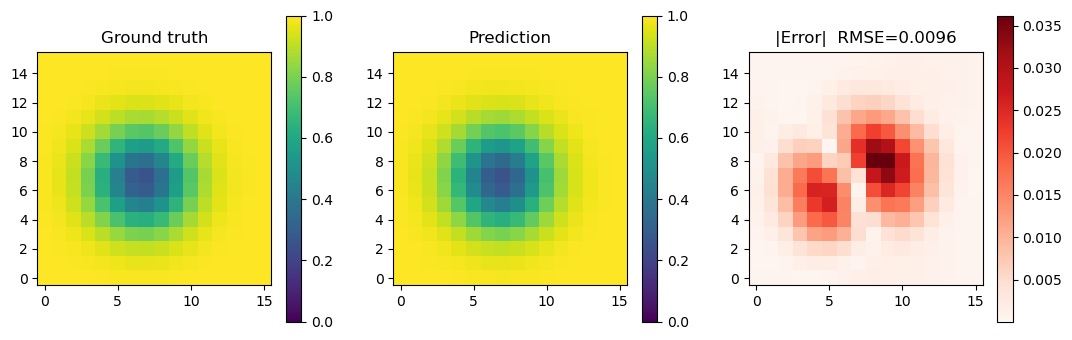

In [ ]:
# import time

# signals_all  = onp.concatenate([
#     onp.load('checkpoint3dataset.npy'),
#     onp.load('checkpoint3dataset_p2.npy'),
# ], axis=0)
# focal_all    = onp.concatenate([
#     onp.load('checkpoint3FocalPoints.npy'),
#     onp.load('checkpoint3FocalPoints_p2.npy'),
# ], axis=0)
# starting_all = onp.concatenate([
#     onp.load('checkpoint3starting.npy'),
#     onp.load('checkpoint3starting_p2.npy'),
# ], axis=0)
# velfield_gt  = onp.concatenate([
#     onp.load('checkpoint3velocityfield16.npy'),
#     onp.load('checkpoint3velocityfield16_p2.npy'),
# ], axis=0)

# test_idx = 2
# sig_ev   = signals_all[test_idx]
# x0, y0   = focal_all[test_idx, 0]
# x1, y1   = focal_all[test_idx, 1]
# t0, t1   = starting_all[test_idx]

# t_start    = time.time()
# field_pred = GroupSolutionCP3(sig_ev, x0, y0, t0, x1, y1, t1)
# elapsed    = time.time() - t_start

# print(f'Inference time: {elapsed:.3f}s')
# print(f'field16 shape:  {field_pred.shape}')

# fig, axes = plt.subplots(1, 3, figsize=(11, 3.5))
# im0 = axes[0].imshow(velfield_gt[test_idx].T, origin='lower', vmin=0, vmax=1, cmap='viridis')
# axes[0].set_title('Ground truth'); plt.colorbar(im0, ax=axes[0])
# im1 = axes[1].imshow(field_pred.T, origin='lower', vmin=0, vmax=1, cmap='viridis')
# axes[1].set_title('Prediction'); plt.colorbar(im1, ax=axes[1])
# err = onp.abs(velfield_gt[test_idx] - field_pred)
# im2 = axes[2].imshow(err.T, origin='lower', cmap='Reds')
# axes[2].set_title(f'|Error|  RMSE={onp.sqrt(onp.mean(err**2)):.4f}')
# plt.colorbar(im2, ax=axes[2])
# plt.tight_layout(); plt.show()


━━━━━━ Validation sui 5 PROF mai visti ━━━━━━


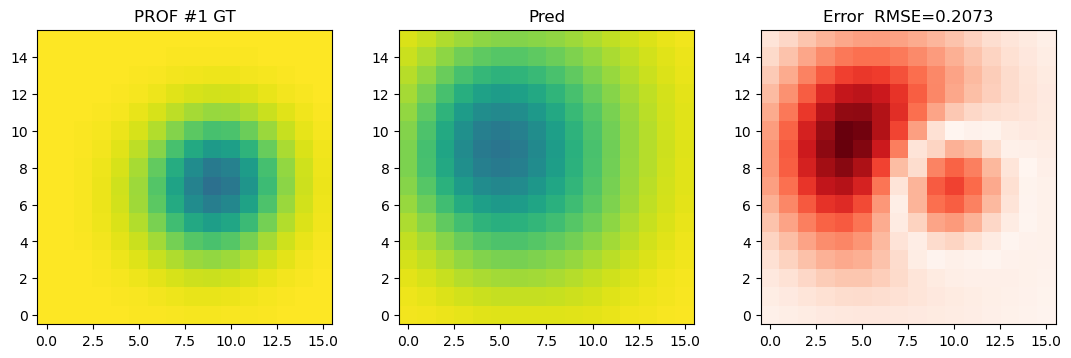

  PROF #1: RMSE = 0.2073


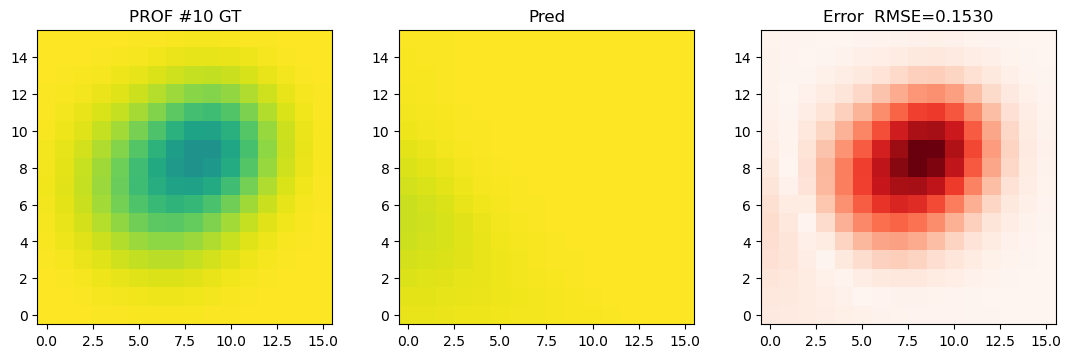

  PROF #10: RMSE = 0.1530


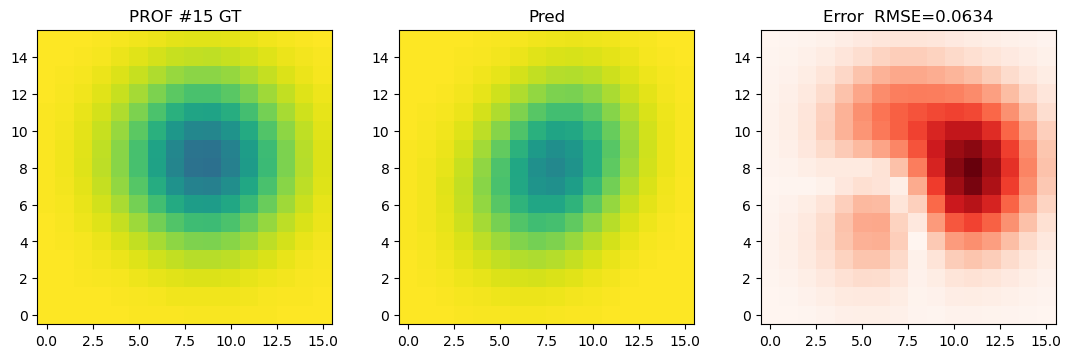

  PROF #15: RMSE = 0.0634


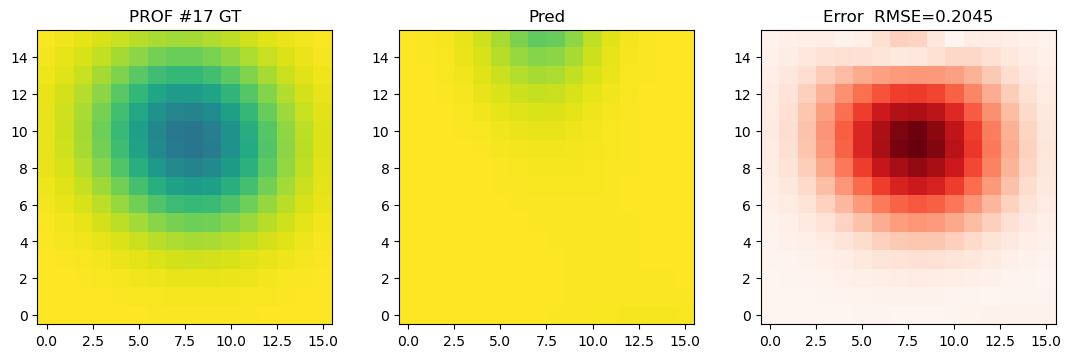

  PROF #17: RMSE = 0.2045


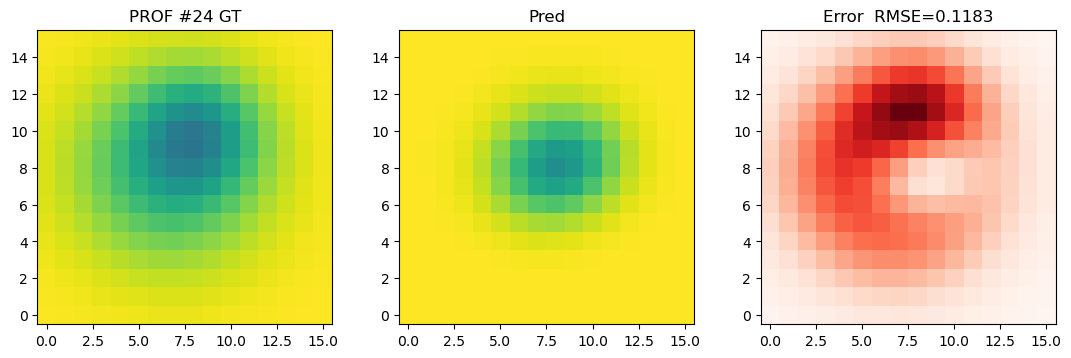

  PROF #24: RMSE = 0.1183

━━━━━━ Validation sui 30 SYNTH mai visti ━━━━━━


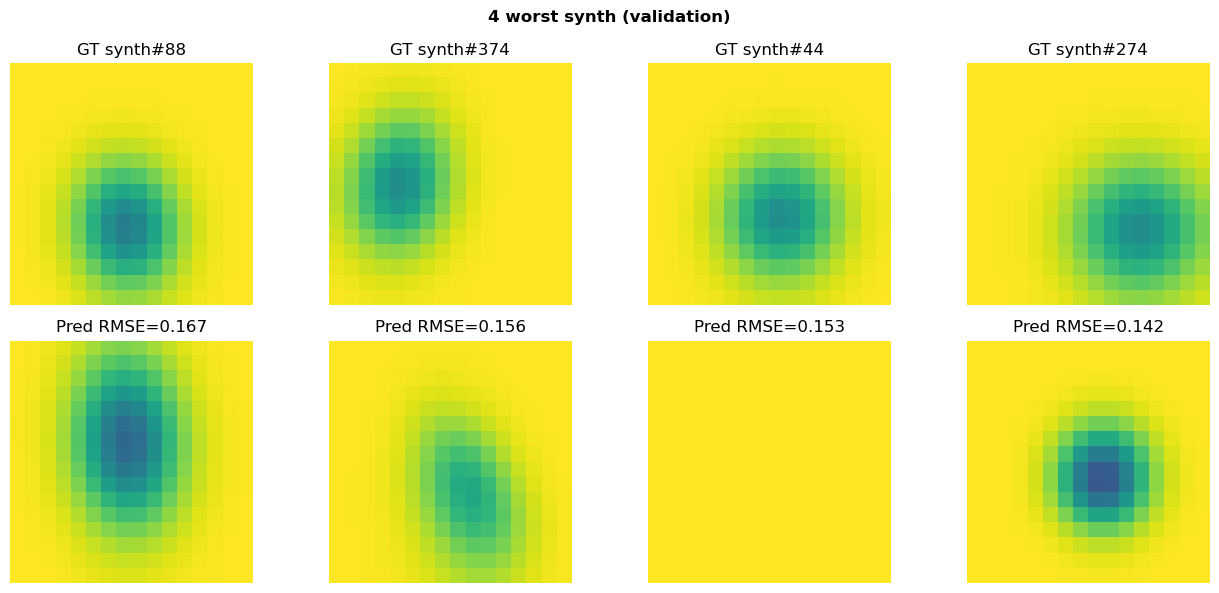


                   PROF (n=5)    SYNTH (n=30)
   Mean RMSE :    0.1493        0.1001
   Std  RMSE :    0.0544        0.0314
   Min  RMSE :    0.0634        0.0412
   Max  RMSE :    0.2073        0.1674


In [ ]:
# # ─────────────────────────────────────────────────────────────────
# # VALIDATION FINALE: 5 prof + 30 synth MAI VISTI dalla rete
# # ─────────────────────────────────────────────────────────────────

# # Carico TUTTI i prof e seleziono solo i 5 di validation
# signals_prof_all = onp.concatenate([
#     onp.load('checkpoint3dataset.npy'),
#     onp.load('checkpoint3dataset_p2.npy'),
# ], axis=0)
# focal_prof_all = onp.concatenate([
#     onp.load('checkpoint3FocalPoints.npy'),
#     onp.load('checkpoint3FocalPoints_p2.npy'),
# ], axis=0)
# starting_prof_all = onp.concatenate([
#     onp.load('checkpoint3starting.npy'),
#     onp.load('checkpoint3starting_p2.npy'),
# ], axis=0)
# velfield_gt_prof_all = onp.concatenate([
#     onp.load('checkpoint3velocityfield16.npy'),
#     onp.load('checkpoint3velocityfield16_p2.npy'),
# ], axis=0)

# # Carico tutti i synth e seleziono solo i 30 di validation
# signals_synth_all  = onp.load('synth_data/synthetic_dataset.npy')
# focal_synth_all    = onp.load('synth_data/synthetic_FocalPoints.npy')
# starting_synth_all = onp.load('synth_data/synthetic_starting.npy')
# velfield_gt_synth_all = onp.load('synth_data/synthetic_velocityfield16.npy')

# # ───── Validation sui 5 PROF ─────
# prof_rmse = []
# print(f'━━━━━━ Validation sui {N_VAL_PROF} PROF mai visti ━━━━━━')
# for k, idx in enumerate(val_prof_idx):
#     sig_ev = signals_prof_all[idx]
#     x0, y0 = focal_prof_all[idx, 0]
#     x1, y1 = focal_prof_all[idx, 1]
#     t0, t1 = starting_prof_all[idx]

#     pred = GroupSolutionCP3(sig_ev, x0, y0, t0, x1, y1, t1)
#     err  = onp.abs(velfield_gt_prof_all[idx] - pred)
#     rmse = onp.sqrt(onp.mean(err**2))
#     prof_rmse.append(rmse)

#     fig, axes = plt.subplots(1, 3, figsize=(11, 3.5))
#     axes[0].imshow(velfield_gt_prof_all[idx].T, origin='lower', vmin=0, vmax=1, cmap='viridis')
#     axes[0].set_title(f'PROF #{idx} GT')
#     axes[1].imshow(pred.T, origin='lower', vmin=0, vmax=1, cmap='viridis')
#     axes[1].set_title('Pred')
#     axes[2].imshow(err.T, origin='lower', cmap='Reds')
#     axes[2].set_title(f'Error  RMSE={rmse:.4f}')
#     plt.tight_layout(); plt.show()
#     print(f'  PROF #{idx}: RMSE = {rmse:.4f}')

# # ───── Validation sui 30 SYNTH ─────
# synth_rmse = []
# print(f'\n━━━━━━ Validation sui {N_VAL_SYNTH} SYNTH mai visti ━━━━━━')
# for k, idx in enumerate(val_synth_idx):
#     sig_ev = signals_synth_all[idx]
#     x0, y0 = focal_synth_all[idx, 0]
#     x1, y1 = focal_synth_all[idx, 1]
#     t0, t1 = starting_synth_all[idx]

#     pred = GroupSolutionCP3(sig_ev, x0, y0, t0, x1, y1, t1)
#     err  = onp.abs(velfield_gt_synth_all[idx] - pred)
#     rmse = onp.sqrt(onp.mean(err**2))
#     synth_rmse.append(rmse)

# # Mostro solo i 4 worst dei synth
# worst_synth = onp.argsort(synth_rmse)[-4:][::-1]
# fig, axes = plt.subplots(2, 4, figsize=(13, 6))
# for col, k in enumerate(worst_synth):
#     idx = val_synth_idx[k]
#     sig_ev = signals_synth_all[idx]
#     x0, y0 = focal_synth_all[idx, 0]; x1, y1 = focal_synth_all[idx, 1]
#     t0, t1 = starting_synth_all[idx]
#     pred = GroupSolutionCP3(sig_ev, x0, y0, t0, x1, y1, t1)
#     axes[0, col].imshow(velfield_gt_synth_all[idx].T, origin='lower', vmin=0, vmax=1, cmap='viridis')
#     axes[0, col].set_title(f'GT synth#{idx}'); axes[0, col].axis('off')
#     axes[1, col].imshow(pred.T, origin='lower', vmin=0, vmax=1, cmap='viridis')
#     axes[1, col].set_title(f'Pred RMSE={synth_rmse[k]:.3f}'); axes[1, col].axis('off')
# plt.suptitle('4 worst synth (validation)', fontsize=12, fontweight='bold')
# plt.tight_layout(); plt.show()

# # ───── Statistiche finali ─────
# print('\n' + '='*55)
# print(f'                   PROF (n={N_VAL_PROF})    SYNTH (n={N_VAL_SYNTH})')
# print(f'   Mean RMSE :    {onp.mean(prof_rmse):.4f}        {onp.mean(synth_rmse):.4f}')
# print(f'   Std  RMSE :    {onp.std (prof_rmse):.4f}        {onp.std (synth_rmse):.4f}')
# print(f'   Min  RMSE :    {onp.min (prof_rmse):.4f}        {onp.min (synth_rmse):.4f}')
# print(f'   Max  RMSE :    {onp.max (prof_rmse):.4f}        {onp.max (synth_rmse):.4f}')
# print('='*55)
